# Expirement running multiple ASP programs multiple times to get mean grounding/solving times

### Loading puzzles

In [270]:
import clingo
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def load_program(puzzle, gen, configuration, base_rules):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined", f"--configuration={configuration}"])
    ctl.load('../solve-experiment.lp')
    ctl.load(f'../{base_rules}')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'../puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    grounded_at = sum(1 for atom in ctl.symbolic_atoms.by_signature('at', 3)) # grounded placements for people at certain locations
    return ctl, ground_time, grounded_at
 
def solve_puzzle(puzzle, gen=False, count=False, configuration='auto', base_rules='base-rules.lp'):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time, grounded_at = load_program(puzzle, gen, configuration, base_rules)
    def on_model(model):
        print(model.symbols(shown=True))
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')
    if count:
        print(f'Number of models: {len(models)}')
        
    print(result)
    print("Satisfiable:", result.satisfiable)
    print("Unsatisfiable:", result.unsatisfiable)
    print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, models, grounded_at

#### Store results

In [325]:
def store_result(results, epoch, puzzle, type, ground_time, solve_time, total_time, grid_size, clue_count, solve_state, num_solutions, choice_type, grounded_at, constraint_type):
    results.append({
        'epoch': epoch, # epoch
        'puzzle': puzzle, # puzzle number
        'type': type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
        'ground_time': ground_time, # time spent on grounding all possibilities
        'solve_time': solve_time, # time spent on solving all grounded rules
        'total_time': total_time, # total time
        'grid_size': grid_size, # grid size of puzzle X*X
        'clue_count': clue_count, # number of clues
        'solve_state': solve_state, # is puzzle satisfiable
        'num_solutions': num_solutions, # number of solutions, should always be 1
        'choice_type': choice_type, # normal
        'grounded_at': grounded_at, # add number of grounded at/3 predicates
        'constraint_type': constraint_type # type of constraint for unique row and col
    })

### Small experiment with dynamic choice rules vs normal choice rules

In [ ]:
epochs=5
puzzles = list(Path('../puzzles_dynamic').glob("puzzle*.lp"))
results_choice = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-dyn.lp')

        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, result.satisfiable, len(models), 'Normal', grounded_at, 'Normal')
        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, result_dyn.satisfiable, len(models_dyn), 'Dynamic', grounded_at_dyn, 'Normal')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
[at(alphonse,1,5), at(bonnie,2,0), at(charlie,8,6), at(daisy,3,2), at(emily,4,8), at(frank,6,7), at(george,7,1), at(hannah,5,4), at(victor,0,3), murderer(alphonse), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M9-55, M, Fals

In [327]:
# put results in pandas frame
df_choice = pd.DataFrame(results_choice)
df_choice.head()

# df_choice[df_choice['choice_type']=='D']

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.191744,0.042980,0.234724,9,10,True,1,Normal,549,Normal
1,0,30,M,0.134184,0.041126,0.175310,9,10,True,1,Dynamic,549,Normal
2,0,55,M,0.156016,0.088466,0.244482,9,14,True,1,Normal,540,Normal
3,0,55,M,0.136926,0.165774,0.302699,9,14,True,1,Dynamic,540,Normal
4,0,45,M,0.146800,0.067556,0.214356,9,12,True,1,Normal,531,Normal


In [328]:
# check for failed solutions or multiple solutions
failed = df_choice[df_choice['solve_state'] == False]
len(failed)

0

In [329]:
# check for failed solutions or multiple (or no) solutions
wrong_sol = df_choice[df_choice['num_solutions'] != 1]
len(wrong_sol)

0

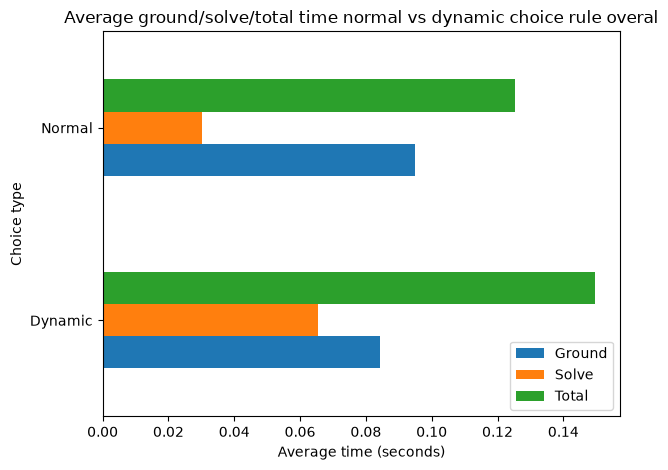

In [330]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby('choice_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule overal')
plt.ylabel('Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

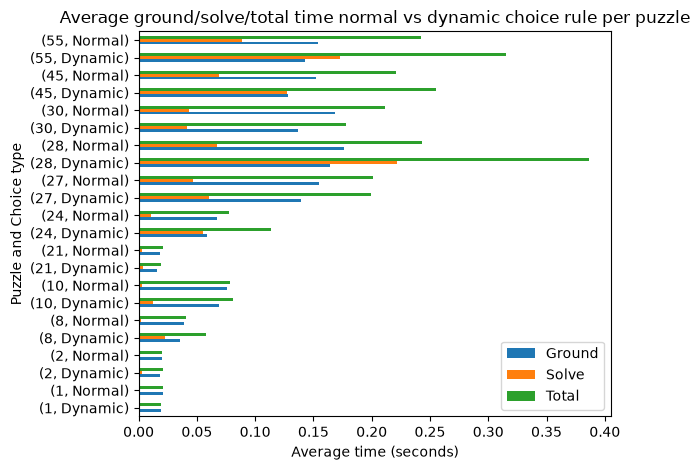

In [331]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby(['puzzle', 'choice_type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule per puzzle')
plt.ylabel('Puzzle and Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

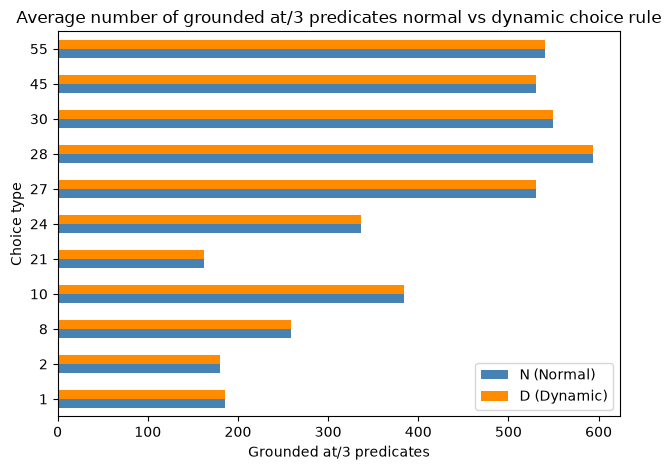

In [332]:
# compare ground_time/solve_time/total_time for both approaches
df_choice.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs dynamic choice rule')
plt.ylabel('Choice type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'D (Dynamic)'])
plt.tight_layout()
plt.show()

#### Small experiment between normal constraints and aggregate constraints
```ASP
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), R1=R2, P1!=P2.
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), C1=C2, P1!=P2.
```

VS

```ASP
:- at(_,_,C), #count{P : at(P,R,C)} != 1.
:- at(_,R,_), #count{P : at(P,R,C)} != 1.
```

In [333]:
epochs=5
puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
results_agg = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, result.satisfiable, len(models), 'Normal', grounded_at, 'Normal')
        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, result_dyn.satisfiable, len(models_dyn), 'Normal', grounded_at_dyn, 'Aggregate')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M9-55, M, False
[at(alice,3,3), at

In [334]:
# put results in pandas dataframe
# put results in pandas frame
df_agg = pd.DataFrame(results_agg)
df_agg.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.182068,0.040985,0.223053,9,10,True,1,Normal,549,Normal
1,0,30,M,0.139816,0.017668,0.157484,9,10,True,1,Normal,549,Aggregate
2,0,55,M,0.152781,0.089895,0.242676,9,14,True,1,Normal,540,Normal
3,0,55,M,0.143532,0.131028,0.274560,9,14,True,1,Normal,540,Aggregate
4,0,45,M,0.149826,0.072412,0.222238,9,12,True,1,Normal,531,Normal


In [335]:
# check for failed solutions or multiple solutions
failed_agg = df_agg[df_agg['solve_state'] == False]
len(failed_agg)

0

In [336]:
# check for failed solutions or multiple solutions
wrong_sol_agg = df_agg[df_agg['num_solutions'] != 1]
len(wrong_sol_agg)

0

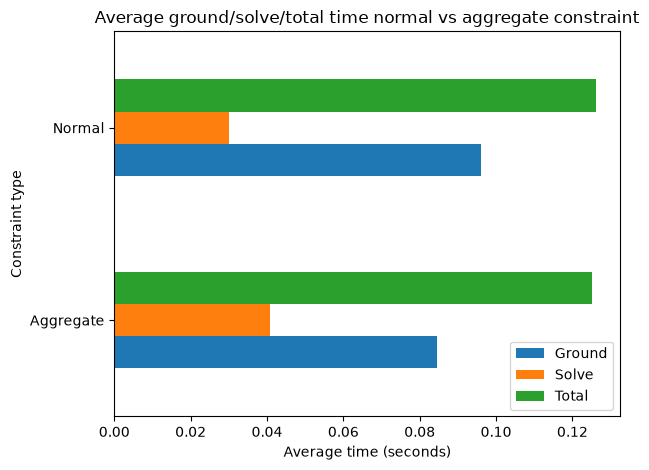

In [339]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs aggregate constraint')
plt.ylabel('Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

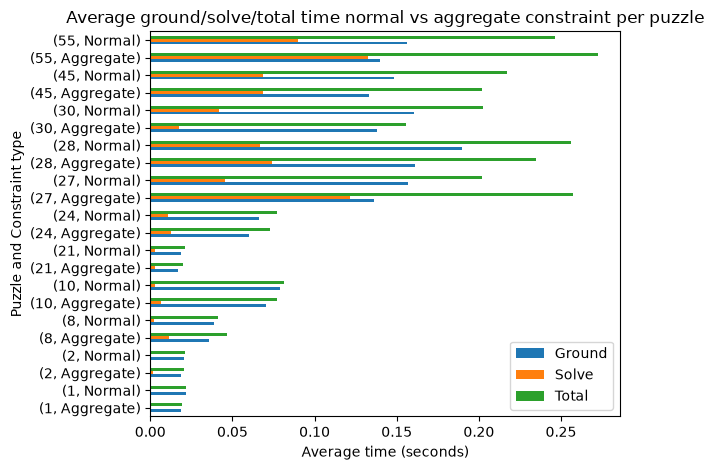

In [340]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby(['puzzle', 'constraint_type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs aggregate constraint per puzzle')
plt.ylabel('Puzzle and Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

For most of the puzzles the aggregate constraints reduce the grounding time, but solving time can drastically increase as well. Maybe compare this on the complete set. There are just 2 puzzles where aggregate constraints take longer in total.
Overall it also shows grounding is faster, but solving is slower, in total there doesn't seem to be a difference in this limited set.

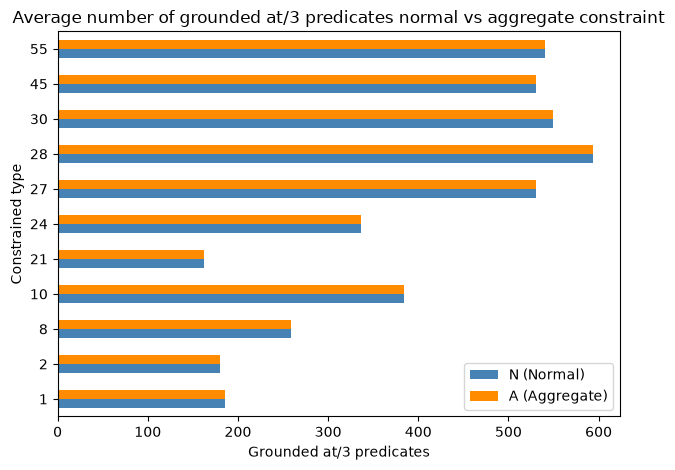

In [342]:
# compare ground_time/solve_time/total_time for both approaches
df_agg.groupby(['puzzle','constraint_type'])[['grounded_at']].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs aggregate constraint')
plt.ylabel('Constrained type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'A (Aggregate)'])
plt.tight_layout()
plt.show()

## Run main experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are stored per puzzle per epoch, these can later be used for analysis
- Python vs ASP vs ASP with aggregate constraints


In [399]:
import sys
import importlib

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

import solver.pythonsolver as pythonsolver


importlib.reload(pythonsolver)


<module 'solver.pythonsolver' from '/Users/jurgen/Code/MASTER_OU/MBAI/project/murdoku-solve/solver/pythonsolver.py'>

In [ ]:
# number of runs for experiment
epochs = 3
debug = True

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])
        if debug:
            print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')

        # run both ASP implementations
        result, ground_time, solve_time, grid_size, clue_count, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        # run python solver:                
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python = pythonsolver.find_solutions(pfile, cfile)

        # store results for 3 methods:
        store_result(results, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate')
        store_result(results, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')
            break

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/3
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(bonnie,2,0), at(charlie,8,6), at(daisy,3,2), at(emily,4,8), at(frank,6,7), at(george,7,1), at(hannah,5,4), at(victor,0,3), murderer(alphonse), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
[at(alphonse,1,5), at(bonnie,2,0), at(charlie,8,6), at(daisy,3,2), at(emily,4,8), at(frank,6,7), at(george,7,1), at(hannah,5,4), at(victor,0,3), murderer(alphonse), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Pu

### Analyze
- convert results to Pandas DataFrame for easy evaluation

#### Error checks
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions

#### Compare results
- Compare performance between puzzles (commented out)
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between generated and manual puzzles
- Compare performance between combination of grid size and number of clues
- Compare performance between combination of grid size and generated/manual

In [410]:
df = pd.DataFrame(results)
df.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.175129,0.041612,0.216741,9,10,True,1,ASP,549.0,Normal
1,0,30,M,0.132498,0.016880,0.149378,9,10,True,1,ASP,549.0,Aggregate
2,0,30,M,0.000283,0.001574,0.001857,9,10,True,1,Python,NaN,Python
3,0,55,M,0.153506,0.100352,0.253859,9,14,True,1,ASP,540.0,Normal
4,0,55,M,0.184547,0.137709,0.322256,9,14,True,1,ASP,540.0,Aggregate


### Compare Python vs ASP vs ASP with aggregate constraint

In [411]:
df.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean()

,ground_time,solve_time,total_time
constraint_type,,,
Aggregate,0.398271,1.813235,2.211506
Normal,0.463222,1.658444,2.121665
Python,0.000348,2.103658,2.104006


In [416]:
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type']).size().sort_values(ascending=False)

puzzle  type  grid_size  constraint_type
1       A     14         Aggregate          1
57      A     5          Aggregate          1
53      A     7          Python             1
55      M     9          Aggregate          1
                         Normal             1
                                           ..
27      A     10         Normal             1
                         Python             1
        M     9          Aggregate          1
                         Normal             1
99      A     8          Python             1
Length: 153, dtype: int64

In [419]:
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time', 'total_time']
].mean().sort_values('total_time', ascending=False).head(30)

ground_time  solve_time  total_time
puzzle type grid_size constraint_type                                     
28     M    9         Python              0.000266   91.607325   91.607591
12     A    14        Aggregate           3.191180   32.611326   35.802506
                      Normal              3.635474   31.783751   35.419225
1      A    14        Normal              3.723955   18.763810   22.487765
                      Aggregate           3.216483   17.137520   20.354004
23     A    12        Aggregate           1.121831   17.812700   18.934531
                      Normal              1.337782    7.038840    8.376622
56     A    12        Normal              1.336132    6.015863    7.351995
58     A    13        Normal              2.308486    3.882356    6.190841
56     A    12        Aggregate           1.185057    4.306629    5.491686
33     A    12        Normal              1.428037    3.667680    5.095717
58     A    13        Python              0.000411    4.847993    4.848404
62     A    12        Aggregate           1.232874    3.288752    4.521626
                      Normal              1.722736    2.675197    4.397933
58     A    13        Aggregate           2.065978    2.322888    4.388866
33     A    12        Aggregate           1.282877    2.574208    3.857085
91     A    12        Normal              1.443119    2.183288    3.626407
56     A    12        Python              0.000389    3.595154    3.595543
27     A    10        Aggregate           0.346429    3.046398    3.392827
29     A    11        Aggregate           0.664569    2.620965    3.285534
                      Normal              0.848771    1.982143    2.830914
45     M    9         Python              0.000264    2.801094    2.801358
91     A    12        Aggregate           1.034545    1.548384    2.582929
27     A    10        Normal              0.383764    2.155230    2.538994
78     A    11        Aggregate           0.679717    1.086797    1.766514
76     A    10        Normal              0.369986    1.343889    1.713875
78     A    11        Normal              0.741145    0.846425    1.587570
76     A    10        Aggregate           0.324478    1.008090    1.332568
13     A    10        Aggregate           0.312487    0.515821    0.828308
27     A    10        Python              0.000329    0.817968    0.818297

In [ ]:
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type'])[['total_time']].mean()

total_time
choice_type grid_size            
Normal      4            0.004315
            5            0.010534
            6            0.022649
            7            0.069534
            8            0.081357
            9            0.295801
            10           1.022263
            11           2.304835
            12           6.292993
            13           5.301885
            14          29.228138
Python      10           0.153813
            11           0.119311
            12           1.001555
            13           4.844493
            14           0.553754
            4            0.000075
            5            0.000124
            6            0.000651
            7            0.003116
            8            0.002910
            9            9.296604

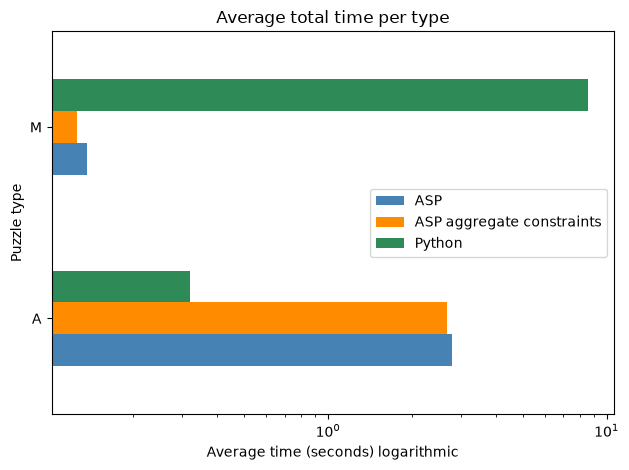

In [421]:
ax = df.groupby(['type', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

ax.set_xscale('log')
plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.title('Average total time per type')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

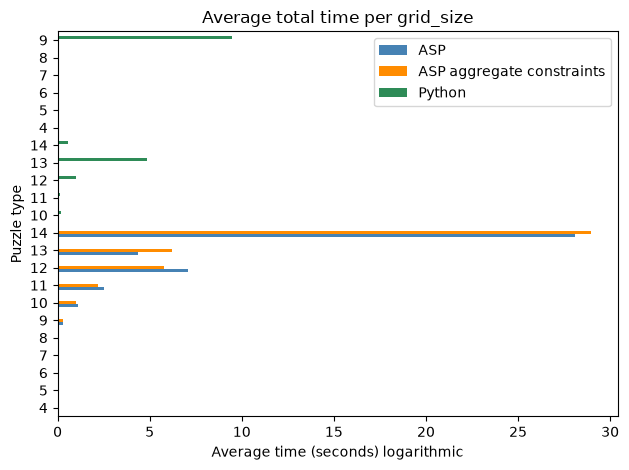

In [422]:
ax = df.groupby(['grid_size', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.title('Average total time per grid_size')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

In [393]:
# unsolved = df[~df['solve_state']]
# unsolved.sum()
(~df['solve_state']).sum()

np.int64(0)

In [394]:
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type


In [375]:
df[(df['puzzle']==1) & (df['grid_size']==11)]

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type


In [240]:
df.groupby('puzzle')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
puzzle,,,
1,0.150346,0.096850,0.247196
2,0.158316,0.743289,0.901605
3,0.175248,0.078590,0.253837
4,0.104929,0.051497,0.156427
5,0.111627,0.086437,0.198064
...,...,...,...
96,0.111725,0.056551,0.168275
97,0.112015,0.084707,0.196722
98,0.108109,0.042743,0.150852


In [241]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003783,0.000329,0.004112
5,0.009235,0.001381,0.010616
6,0.021491,0.003923,0.025414
7,0.046995,0.014286,0.061282
8,0.096156,0.051067,0.147223
9,0.191893,0.135699,0.327592
10,0.361391,0.591928,0.953319
11,0.645106,2.302929,2.948034


In [242]:
# df.groupby('puzzle')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

# plt.ylabel('Puzzle')
# plt.xlabel('Average time (seconds)')
# plt.title('Average ground/solve/total time per puzzle')
# plt.legend(['Ground', 'Solve', 'Total'])
# plt.tight_layout()
# plt.show()

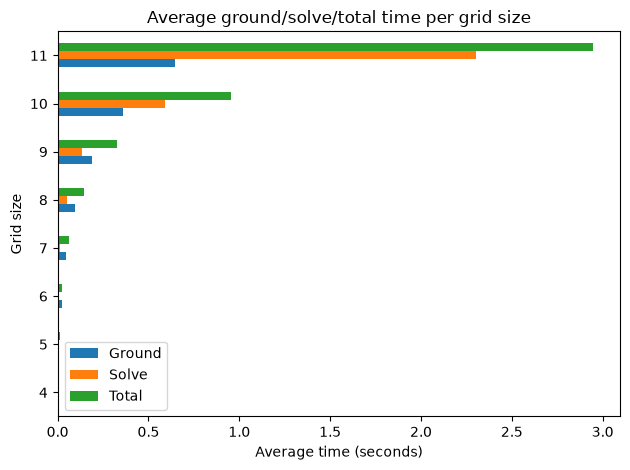

In [243]:
df.groupby('grid_size')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

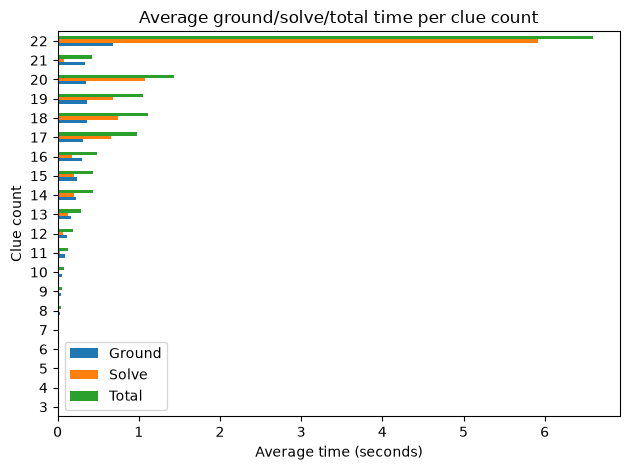

In [244]:
df.groupby('clue_count')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

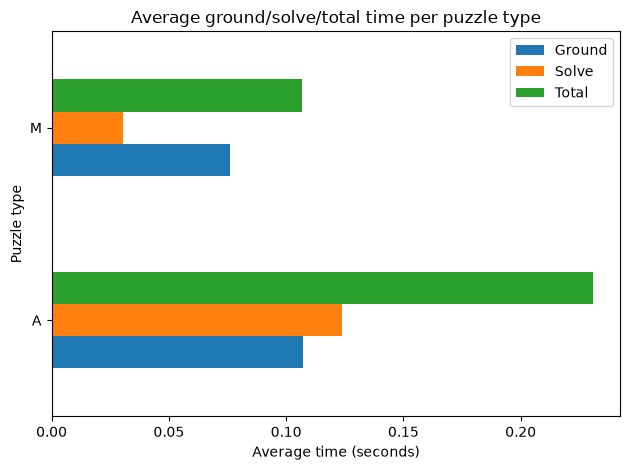

In [245]:
df.groupby('type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

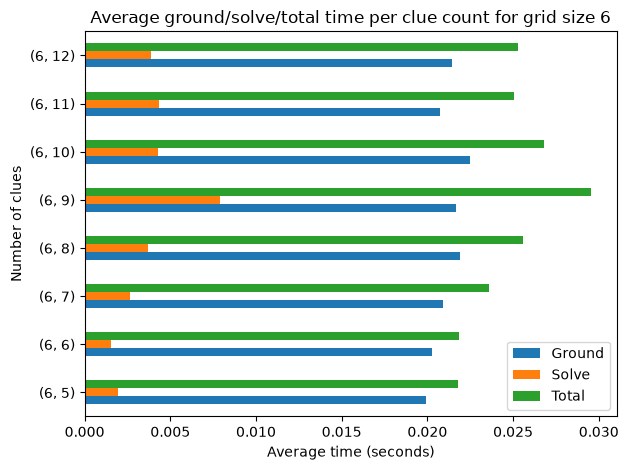

In [246]:
df_6 = df[df['grid_size'] == 6]
df_6.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Number of clues')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 6')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

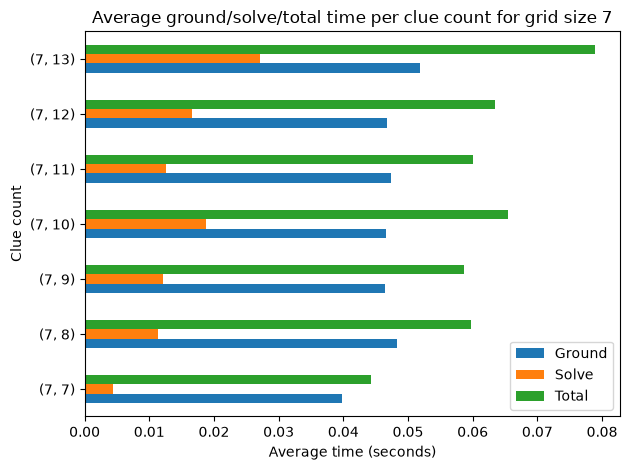

In [247]:
df_7 = df[df['grid_size'] == 7]
df_7.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 7')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

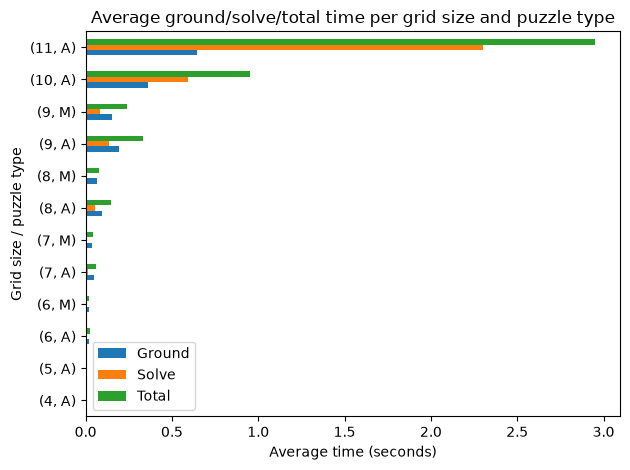

In [248]:
df.groupby(['grid_size', 'type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size / puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size and puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()